# Quickstart

This page is the first step of the beginner route through mboostrs, for readers
who know linear regression and have fitted a model to a data frame; it assumes no
knowledge of boosting. It takes one simulated data set through a direct fit with
`gamboost`, tuning of the stopping iteration `mstop` by cross-validation,
interpretation by coefficients and partial effects, and prediction.
Installation is on the [previous page](install.ipynb). The next page,
[Five modelling decisions](five_decisions.ipynb), explains the choices of
target, family, term shape, stopping rule and diagnostics that this page makes
with default settings. Automated term choice and specification search are
advanced topics, listed under Advanced in the table of contents.

````{admonition} 30-second version
:class: tip

```python
import numpy as np
import mboostrs as mb

rng = np.random.default_rng(0)
n = 400
x1 = rng.normal(size=n)
x2 = rng.normal(size=n)
y = 1.5 * x1 + np.sin(2 * x2) + rng.normal(scale=0.3, size=n)
data = {"x1": x1, "x2": x2, "y": y}

fit = mb.gamboost("y ~ bols(x1) + bbs(x2)", data=data, family=mb.Gaussian(),
                  control=mb.boost_control(mstop=300, nu=0.1))
cvr = fit.cvrisk(type="kfold", B=5)
fit = fit[:cvr.optimal_mstop]
fit.coef()            # aggregated coefficients
fit.plot_risk()       # risk path
fit.plot_selected()   # which learners won each iteration
fit.plot_partial_effects()  # smooth term shapes
```
````

```{admonition} Component-wise updates
:class: tip
[](../methodology/worked_example) traces the first five iterations of a
six-observation fit by hand (offset, pseudo-residual, per-learner SSE, selection,
update) and verifies the numbers against the engine. This page runs the same
workflow at $n=400$; the worked example runs it at $n=6$, where every step fits
on one page.
```

In [1]:
import numpy as np
import polars as pl
import mboostrs as mb

rng = np.random.default_rng(0)
n = 400
x = rng.normal(size=n)
z = rng.normal(size=n)
noise = rng.normal(scale=0.3, size=n)
y = 1.5 * x + np.sin(2 * z) + noise          # linear effect of x, smooth in z
data = pl.DataFrame({"x": x, "z": z, "y": y})

## Fit an additive model

A formula combines base learners with `+`. Here a **linear** term in `x`
(`bols`) and a **P-spline** in `z` (`bbs`). A P-spline is a smooth curve built
from B-spline basis functions with a roughness penalty; `df=4` sets its
effective degrees of freedom, which is its flexibility:

In [2]:
fit = mb.gamboost(
    "y ~ bols(x) + bbs(z, df=4)",
    data=data,
    family=mb.Gaussian(),
    control=mb.boost_control(mstop=300, nu=0.1),
)
fit

GAMBoostModel(formula='y ~ bols(x) + bbs(z, df=4)', family=Gaussian, mstop=300)

## Inspect the risk path

The in-bag risk is the loss summed over the training rows used in the fit. It
drops quickly and flattens:

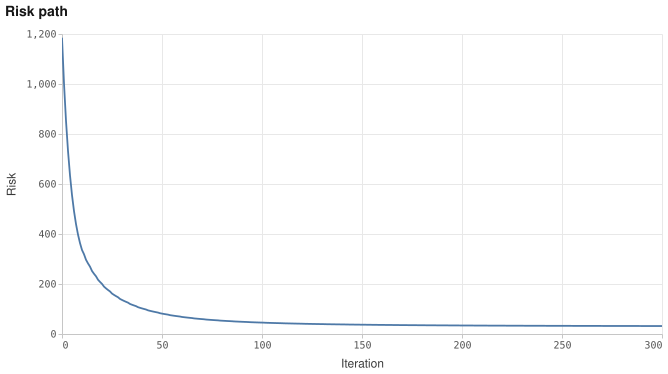

In [3]:
fit.plot_risk()

## Selection frequency

`plot_selected` counts the iterations in which each base learner was selected:

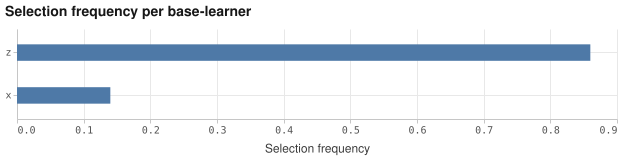

In [4]:
fit.plot_selected()

The linear `bols(x)` term is selected more often than the smooth `bbs(z)`,
because the signal in `x` is stronger relative to the noise.

## Choose the stopping iteration by cross-validated risk

`mstop` is the number of boosting iterations and the main regularizer: stopping
earlier gives a simpler fit. Choose it with `cvrisk`:

In [5]:
cvr = fit.cvrisk(type="kfold", B=5, seed=42)
m_opt = cvr.optimal_mstop
m_opt

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 300 is within 5% of the search cap 300; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(
/tmp/ipykernel_67962/2325050004.py:1: RuntimeWarning: the cross-validated risk is still falling at mstop=300, the largest iteration evaluated, so the reported optimal_mstop=300 is where the path stopped rather than where the risk turns. Refit with a larger mstop and cross-validate again on the same folds: `model.continue_to(600)` then `cvrisk(folds=...)`. (`continue_to` resumes the retained gradient where the fit kept one, and otherwise costs a full path; `parity_notes(include_global=True)` says which routes resume.)
  cvr = fit.cvrisk(type="kfold", B=5, seed=42)


300

The selected `mstop` is 300, equal to the largest value in the search (`mstop=300` in the fit), and `cvrisk` issued warnings that the search range was exhausted. The cross-validated risk was still falling at 300, so the best value on a longer grid may be larger than 300; `fit.continue_to(600)` followed by `cvrisk` on the same folds would test that.

## Predict

`predict` returns values on the scale you ask for. `type="link"` gives the
linear predictor: the offset plus the sum of the selected base-learner
effects. `type="response"` applies the family's response function, so the
numbers come back on the scale of `y` itself.

For a Gaussian fit the two agree, because the link is the identity. For
`Binomial`, `type="link"` returns half the log-odds, following mboost's
response coding; `type="response"` returns `1 / (1 + exp(-2 * f))`,
the event probability for link prediction `f`. Every family's
response scale is a column in `mb.family_capabilities()`.

`mstop=` reads the prediction off that position of the path without refitting
and leaves `fit` unchanged.

In [6]:
yhat = fit.predict(newdata=data, mstop=m_opt, type="response")
rmse = np.sqrt(np.mean((yhat - y) ** 2))
print(f"in-sample RMSE at m_opt={m_opt}: {rmse:.3f}")

in-sample RMSE at m_opt=300: 0.282


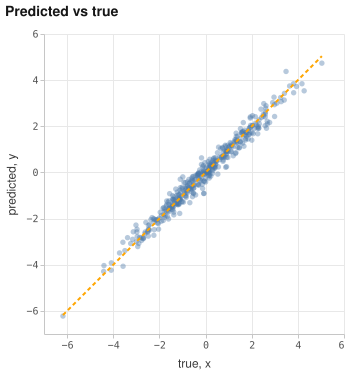

In [7]:
import polars as pl
import altair as alt
df_compare = pl.DataFrame({"true": y, "predicted": yhat})
alt.Chart(df_compare).mark_circle(opacity=0.4).encode(
    x="true", y="predicted"
).properties(title="Predicted vs true") + alt.Chart(
    pl.DataFrame({"x": [y.min(), y.max()], "y": [y.min(), y.max()]})
).mark_line(color="orange", strokeDash=[4, 3]).encode(x="x", y="y")

## Diagnose the fit

Cross-validation chooses the stopping iteration within the specified model.
Residual plots help assess whether its terms represent the response adequately.
For this Gaussian example, plot response residuals, `y - fitted`, against each
predictor. A systematic curve suggests an effect the fitted terms have missed;
residual scatter without a curve is consistent with an adequate mean model.

Below, the same data is fitted twice: once with `bbs(z, df=4)`, which can bend,
and once with `bols(z)`, which cannot. `y` was built with `sin(2 * z)` in it.

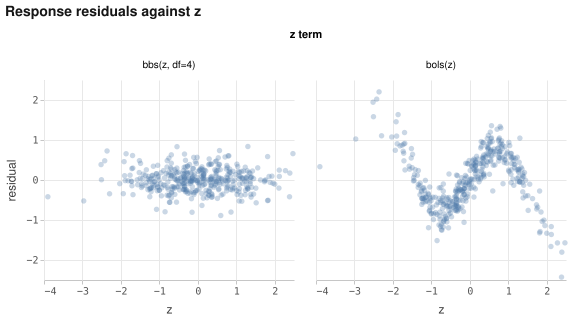

In [8]:
resid = fit.residual_frame(kind="response", mstop=m_opt)

straight = mb.gamboost(                     # deliberately wrong: z is smooth
    "y ~ bols(x) + bols(z)",
    data=data,
    family=mb.Gaussian(),
    control=mb.boost_control(mstop=300, nu=0.1),
)
resid_straight = straight.residual_frame(kind="response", mstop=300)

points = pl.DataFrame({
    "z": np.concatenate([z, z]),
    "residual": np.concatenate([resid["residual"], resid_straight["residual"]]),
    "z term": ["bbs(z, df=4)"] * n + ["bols(z)"] * n,
})
alt.Chart(points).mark_circle(opacity=0.3).encode(
    x="z", y="residual", column="z term",
).properties(width=250, height=200,
            title="Response residuals against z")

The residuals from the smooth fit show no systematic pattern in the left panel.
The straight-line fit leaves a sinusoidal pattern in the right panel. Because this example was
simulated with `sin(2 * z)`, we can also calculate each fit's residual correlation
with that omitted shape:

In [9]:
for name, frame in (("bbs(z, df=4)", resid), ("bols(z)", resid_straight)):
    r = np.corrcoef(frame["residual"], np.sin(2 * z))[0, 1]
    sd = float(frame["residual"].std())
    print(f"{name:>14}: corr(residual, sin(2z)) = {r:+.3f}, residual sd = {sd:.3f}")

  bbs(z, df=4): corr(residual, sin(2z)) = +0.067, residual sd = 0.283
       bols(z): corr(residual, sin(2z)) = +0.829, residual sd = 0.682


The residual correlation with `sin(2z)` is 0.83 for the straight-line fit and
0.07 for the smooth fit, and the straight-line fit's residual standard deviation
is more than twice as large. In real data you
do not know the generating function, so the general form is: residuals against
each predictor, against the fitted values, and — if the rows are ordered in
time — against their order. `fit.plot_residuals()` draws the standard set, and
[](diagnostics.ipynb) covers the checks that go beyond a Gaussian mean, such as
the PIT histogram and worm plot for a distributional fit.

Some checks are not available for every model. The fitted object reports which
operations it cannot run:

In [10]:
final = fit.with_mstop(m_opt)
print("sliced out of the path:", final.unavailable_operations() or "nothing refused")

restored = mb.load_model(mb.save_model(fit, "quickstart_fit.json"))
print("read back from an artifact:")
for entry in restored.unavailable_operations():
    print(f"  {entry['operation']}: {entry['needs']}")


sliced out of the path: nothing refused


read back from an artifact:
  continue_to: grows the path by refitting to a larger mstop
  cvrisk: refits on each fold's in-bag weights
  stabsel: refits on each subsample
  confint: refits on bootstrap resamples
  conformal_interval: refits on a calibration split
  update: refits when asked for an mstop larger than the fitted one; slicing to a smaller one still works


`final` retains the training inputs after slicing, so it can still run
cross-validation, bootstrap intervals, and extend the boosting path.
`mb.load_model` restores the fitted coefficients without the training data;
operations that require a refit then raise an error explaining which input is
missing. `predict`, `coef`, `residual_frame`, and partial effects are available
on both objects.


## Selected learners and coefficients

`coef` returns the aggregated coefficient of each selected base learner;
`selected` is the per-iteration selection sequence. A component that is never
the best-fitting learner in any iteration is never selected, so boosting
performs variable selection as part of fitting.

In [11]:
print("selected (first 10 iterations):", fit.selected[:10])
print("offset:", round(fit.offset_, 4))
fit.coef()

selected (first 10 iterations): ['x', 'x', 'x', 'x', 'x', 'x', 'x', 'x', 'x', 'x']
offset: -0.0754


{'x': array([0.05490249, 1.49924965]),
 'z': array([-0.76417316, -0.3560076 ,  0.04586948,  0.41001563,  0.69869992,
         0.87165365,  0.87634957,  0.67735643,  0.28832725, -0.23269229,
        -0.7290367 , -0.99543269, -0.90663345, -0.48613572,  0.110833  ,
         0.66059086,  0.96753115,  0.94021161,  0.63432488,  0.16309975,
        -0.37549725, -0.92583535, -1.47226853, -2.01686455]),
 '(offset)': -0.0753827171092894}

## Partial effects

The smooth term in `z` is nonlinear; `partial_effects` evaluates each learner's
contribution so you can plot it. The built-in `plot_partial_effects` handles the
layout automatically:

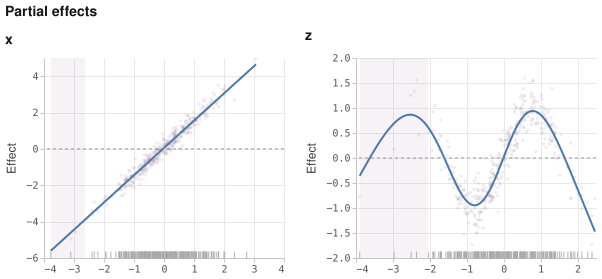

In [12]:
fit.plot_partial_effects()

For custom plots, use `fit.partial_effects()` directly:

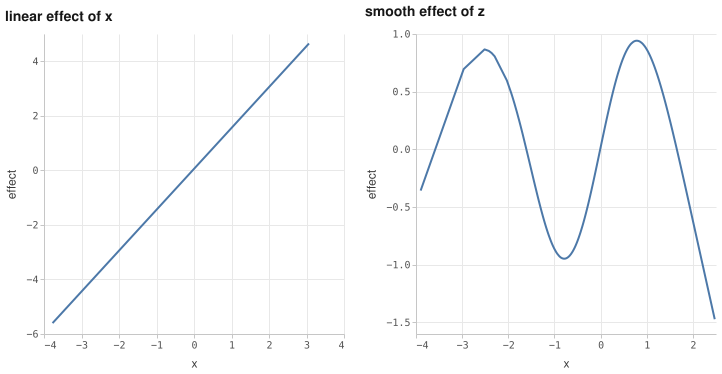

In [13]:
eff = fit.partial_effects()          # name -> (x_values, effect_values)
xx, yx = eff["x"]; ox = np.argsort(xx)
xz, yz = eff["z"]; oz = np.argsort(xz)
import polars as pl
import altair as alt
c1 = alt.Chart(pl.DataFrame({"x": xx[ox], "effect": yx[ox]})).mark_line().encode(x="x", y="effect").properties(title="linear effect of x")
c2 = alt.Chart(pl.DataFrame({"x": xz[oz], "effect": yz[oz]})).mark_line().encode(x="x", y="effect").properties(title="smooth effect of z")
alt.hconcat(c1, c2)

```{figure} ../figures/mermaid-320b566771c2.svg
:name: mermaid-320b566771c2
:alt: Quickstart workflow from fitting and cross-validation through optimal stopping and path truncation to model summaries and diagnostics.

Cross-validation selects the stopping iteration; the truncated path then supplies coefficients, predictions, and diagnostics.
```


In [14]:
fit_opt = fit.with_mstop(m_opt)
print("mstop:", fit_opt.mstop)
print("selected names:", fit_opt.selected_which()[:5])
print("coefficient keys:", list(fit_opt.coef().keys()))

mstop: 300
selected names: ['x', 'x', 'x', 'x', 'x']
coefficient keys: ['x', 'z', '(offset)']


In [15]:
import polars as pl

mb.family_capabilities(output="polars").filter(
    pl.col("name").is_in(["Gaussian", "Binomial", "GaussianLSS"])
).select(["name", "kind", "predict_response", "diagnostics"])

name,kind,predict_response,diagnostics
str,str,str,str
"""Binomial""","""standard""","""yes""","""partial"""
"""Gaussian""","""standard""","""yes""","""partial"""
"""GaussianLSS""","""lss""","""yes""","""partial"""


1. Fit a long enough path.
2. Choose or inspect `mstop`.
3. Work with `fit.with_mstop(k)` or `fit[:k]`.
4. Interpret selected learners, coefficients, partial effects, and diagnostics
   at that path position.

## The same workflow in R

The **R binding** mirrors the Python API. Names differ only by language
convention (`.` in R, `_` in Python; no trailing underscore for `fitted`):

```r
library(mboostrs)

set.seed(0)
n <- 400
x <- rnorm(n); z <- rnorm(n); noise <- rnorm(n, sd = 0.3)
y <- 1.5 * x + sin(2 * z) + noise
data <- data.frame(x = x, z = z, y = y)

# 1. Fit a long path.
fit <- gamboost(
  y ~ bols(x) + bbs(z, df = 4),
  data = data,
  family = Gaussian(),
  control = boost_control(mstop = 300, nu = 0.1)
)

# 2. Choose mstop by cross-validated risk.
cvr <- cvrisk(fit, fold_type = "kfold", b = 5)
m_opt <- mstop(cvr)

# 3. Truncate the path to it.
final <- fit[m_opt]

# 4. Interpret at that position.
yhat <- predict(final, newdata = data, type = "response")
cat("in-sample RMSE:", sqrt(mean((yhat - y)^2)), "\n")

coef(final)
```

The R code follows the same four steps. `fit[m_opt]` is R's spelling of
`fit[:k]`, and `mstop(cvr)` is R's spelling of `cvr.optimal_mstop`.

## See also

- [](interface_map.ipynb) — how the interfaces, families, learners, and outputs fit together.
- [](glmboost.ipynb) — the linear/GLM special case and its coefficient paths.
- [](gamboost.ipynb) and [](base_learners.ipynb) — the full additive toolbox.
- [](families.ipynb) — losses beyond the Gaussian mean.
- [](model_selection.ipynb) — `cvrisk` in depth, and `AIC`.
- [](diagnostics.ipynb) — residuals, calibration checks, distributional diagnostics.
- [](plotting_serialization.ipynb) — all built-in plots (risk path, variable importance, AIC, residuals, confidence bands, LSS, multinomial).
- [](gamboostlss.ipynb) — modeling the mean, scale and shape of a response distribution.
- [](r_migration.ipynb) — full R-to-Python mapping table.
- [](install.ipynb) — platform support and troubleshooting.
- [](../implementation/parity_and_bugs) — known differences from R's mboost.

The next page to read is [Five modelling decisions](five_decisions.ipynb).